# 第 38 课｜缺失值处理与可交易性

本 Notebook 对应「365 天量化金融」第 38 课。课程代码主线来自本地视频、课件截图和 Whisper 口播整理；在此基础上补充量化数据语义、断言、性能验证和方法边界。

- 图文口播：`/Users/mojiawen/Documents/学习资料归档/_暂存/pam-video-captures/365-days-quant-finance/38_youtube-6z6aaxjGZcA/index.html`
- 环境：`pkm-quant`
- 数据：固定随机种子生成的离线模拟行情（**非真实股票数据**）
- 状态：可运行学习稿；不代表策略收益承诺

> **数据声明**：本 Notebook 的证券名称、价格和成交量均为教学模拟数据。它用于稳定复现计算方法，不能用于评价真实证券、市场规律或策略收益。

## 本节量化问题

行情中的 `NaN` 可能代表停牌、未上市、退市、交易日历不一致或数据源故障。它们在表格里都显示为空，但回测规则完全不同。

本节重点不是“把空格填满”，而是回答：

1. 缺失发生在哪里、持续多久、原因是什么；
2. `ffill`、`bfill`、普通插值和时间插值分别使用什么信息；
3. 为什么估值价格、原始价格和可交易状态必须分开；
4. 如何按数据真正的公布时间构造无未来信息特征。

### 输入与预期输出

- 小例子：确定 Series，用于核对三种填补和时间插值；
- 完整行情：从模拟日线中截取 `484 日 × 4 股票`，人工注入连续 12 日教学缺口；
- 输出：缺失审计、完整样本损失、停牌估值/交易状态表、point-in-time 宏观对齐；
- 验收：缺失位置、填补结果、删除行数、复牌跳空和公布日前不可用状态均有断言。

## 本节数据是什么？

`daily_prices.csv` 是固定随机种子生成的模拟行情，不是真实证券数据。连续 12 日缺失由本 Notebook **人工注入**，只能称为“教学缺口”，不能冒充真实停牌。

后面的停牌和宏观发布日期例子也由代码直接构造，用于稳定演示业务规则，不评价任何真实公司、市场或数据供应商。

In [1]:
from pathlib import Path
import json
import os
import platform
import sys
import tempfile
import timeit

# Matplotlib 首次运行需要写字体缓存；放到可写临时目录，避免污染用户目录。
MPL_CACHE_DIR = Path(tempfile.gettempdir()) / "pkm-quant-matplotlib"
MPL_CACHE_DIR.mkdir(parents=True, exist_ok=True)
os.environ.setdefault("MPLCONFIGDIR", str(MPL_CACHE_DIR))

import matplotlib.pyplot as plt
from matplotlib import font_manager
import numpy as np
import pandas as pd
import seaborn as sns

# 从本机字体中选择支持中文的字体，避免标题显示成方框。
preferred_chinese_fonts = [
    "PingFang SC",
    "Arial Unicode MS",
    "Hiragino Sans GB",
    "Heiti SC",
]
available_font_names = {font.name for font in font_manager.fontManager.ttflist}
chinese_font = next(
    (name for name in preferred_chinese_fonts if name in available_font_names),
    "DejaVu Sans",
)
plt.rcParams["font.sans-serif"] = [chinese_font, "DejaVu Sans"]
plt.rcParams["axes.unicode_minus"] = False

def find_project_root():
    cwd = Path.cwd().resolve()
    candidates = [
        cwd,
        cwd / "实验" / "p2-python-toolchain",
        cwd / "p2-python-toolchain",
        *cwd.parents,
    ]
    for candidate in candidates:
        if (candidate / "课程辅助设计.md").exists():
            return candidate
    raise FileNotFoundError("请从 p2-python-toolchain 或量化交易项目目录启动 JupyterLab")

PROJECT_ROOT = find_project_root()
DATA_DIR = PROJECT_ROOT / "data" / "fixtures"
OUTPUT_DIR = PROJECT_ROOT / "outputs"
OUTPUT_DIR.mkdir(exist_ok=True)
RANDOM_SEED = 365

print("Python:", sys.version.split()[0])
print("解释器:", sys.executable)
print("项目:", PROJECT_ROOT)
print("绘图字体:", chinese_font)

Python: 3.11.15
解释器: /opt/homebrew/Caskroom/miniforge/base/envs/pkm-quant/bin/python
项目: /Users/mojiawen/Documents/学习资料归档/_暂存/personal_knowledge_manager/量化交易/实验/p2-python-toolchain
绘图字体: PingFang SC


## 小例子：缺失值不能用等号判断

IEEE 浮点 `NaN` 不等于自身，因此 `value == np.nan` 不是可靠判断。pandas 应使用 `pd.isna()` / `pd.notna()`；它们也能识别 `None`、`NaT` 和 `pd.NA`。

对 Series 使用 `.isna()` 会得到同 shape 布尔掩码，`.sum()` 才是缺失数量。

In [2]:
# 构造含 3 个缺失位置的确定 Series，并展示缺失掩码。
missing_demo = pd.Series(
    [10.0, np.nan, np.nan, 13.0, np.nan, 15.0],
    name="原始值",
)
missing_mask = missing_demo.isna()

assert np.nan != np.nan
assert pd.isna(np.nan)
assert missing_demo.isna().sum() == 3
assert missing_mask.tolist() == [
    False, True, True, False, True, False
]

pd.DataFrame(
    {
        "原始值": missing_demo,
        "isna": missing_mask,
    }
)

,原始值,isna
0,10.0,False
1,NaN,True
2,NaN,True
3,13.0,False
4,NaN,True
5,15.0,False


## 同一缺口的三种处理

| 方法 | 信息来源 | 本例含义 |
|---|---|---|
| `ffill()` | 最近一个过去有效值 | `[10,10,10,13,13,15]` |
| `bfill()` | 下一个未来有效值 | `[10,13,13,13,15,15]` |
| `interpolate()` | 缺口两侧端点 | `[10,11,12,13,14,15]` |

`ffill` 没有显式读取未来，但可能制造陈旧价格；`bfill` 和双侧插值若用于缺口时点的交易信号，会直接使用未来信息。

In [3]:
# 并排计算三种方法，并用确定数组核对每个位置。
filled_demo = pd.DataFrame(
    {
        "原始值": missing_demo,
        "ffill": missing_demo.ffill(),
        "bfill": missing_demo.bfill(),
        "linear_interpolate": missing_demo.interpolate(),
    }
)

np.testing.assert_allclose(
    filled_demo["ffill"].to_numpy(),
    [10, 10, 10, 13, 13, 15],
)
np.testing.assert_allclose(
    filled_demo["bfill"].to_numpy(),
    [10, 13, 13, 13, 15, 15],
)
np.testing.assert_allclose(
    filled_demo["linear_interpolate"].to_numpy(),
    [10, 11, 12, 13, 14, 15],
)
filled_demo

,原始值,ffill,bfill,linear_interpolate
0,10.0,10.0,10.0,10.0
1,NaN,10.0,13.0,11.0
2,NaN,10.0,13.0,12.0
3,13.0,13.0,13.0,13.0
4,NaN,13.0,15.0,14.0
5,15.0,15.0,15.0,15.0


## 普通插值与按时间插值

普通 `interpolate()` 把相邻行位置视为等距；`interpolate(method="time")` 按 DatetimeIndex 的实际时间距离分配变化。

下面的日期间隔为 1、3、3、1 天，因此两种结果不同。时间插值前应保证索引单调递增且唯一。两种方法都使用最后的 `108`，所以都不适合作为缺口期间的实时交易信号。

In [4]:
# 在不等间隔日期上对比按位置和按实际时间插值。
time_demo = pd.Series(
    [100.0, np.nan, np.nan, np.nan, 108.0],
    index=pd.to_datetime(
        [
            "2024-01-01",
            "2024-01-02",
            "2024-01-05",
            "2024-01-08",
            "2024-01-09",
        ]
    ),
    name="原始值",
)
assert time_demo.index.is_monotonic_increasing
assert time_demo.index.is_unique

position_interpolation = time_demo.interpolate()
time_interpolation = time_demo.interpolate(method="time")

np.testing.assert_allclose(
    position_interpolation.to_numpy(),
    [100, 102, 104, 106, 108],
)
np.testing.assert_allclose(
    time_interpolation.to_numpy(),
    [100, 101, 104, 107, 108],
)
pd.DataFrame(
    {
        "原始值": time_demo,
        "按位置插值": position_interpolation,
        "按时间插值": time_interpolation,
    }
)

,原始值,按位置插值,按时间插值
2024-01-01,100.0,100.0,100.0
2024-01-02,NaN,102.0,101.0
2024-01-05,NaN,104.0,104.0
2024-01-08,NaN,106.0,107.0
2024-01-09,108.0,108.0,108.0


## 回到完整模拟行情：先看原始数据

先读取原始模拟长表并展示首日记录，再重排成价格宽表。此时尚未注入缺失。

In [5]:
# 读取模拟行情，并展示首个日期的全部虚构股票。
daily = pd.read_csv(
    DATA_DIR / "daily_prices.csv",
    parse_dates=["date"],
)
first_date = daily["date"].min()
first_date_rows = daily.loc[
    daily["date"].eq(first_date),
    ["date", "symbol", "sector", "adj_close", "volume"],
]

assert daily.shape == (4536, 9)
assert daily["date"].nunique() == 756
assert daily["symbol"].nunique() == 6
first_date_rows

,date,symbol,sector,adj_close,volume
0,2023-01-03,BANK_A,金融,11.7218,2822797
756,2023-01-03,INSURE_A,金融,41.7118,2075343
1512,2023-01-03,EV_A,新能源,27.5575,5113762
2268,2023-01-03,POWER_A,公用事业,8.0817,3733504
3024,2023-01-03,ENERGY_A,能源,6.0296,5425851
3780,2023-01-03,TECH_A,科技,36.2134,6241108


## 构造 `484 日 × 4 股票`完整价格面板

先由原始表生成无缺失价格矩阵，再选前 484 个交易日和 4 只股票。这个副本是注入教学缺口前的基准。

In [6]:
# 从完整价格矩阵中确定性选择 484 日和 4 只虚构股票。
close_full = daily.pivot(
    index="date",
    columns="symbol",
    values="adj_close",
).sort_index()
selected_symbols = [
    "BANK_A",
    "ENERGY_A",
    "EV_A",
    "INSURE_A",
]
complete_prices = close_full.loc[
    :,
    selected_symbols,
].iloc[:484].copy()

assert complete_prices.shape == (484, 4)
assert complete_prices.notna().all().all()
complete_prices.head()

symbol,BANK_A,ENERGY_A,EV_A,INSURE_A
date,,,,
2023-01-03,11.7218,6.0296,27.5575,41.7118
2023-01-04,11.6934,6.0138,27.5189,41.9968
2023-01-05,11.6864,6.0281,27.8166,41.7611
2023-01-06,11.6461,6.1016,28.7476,42.6564
2023-01-09,11.4919,6.0260,28.3860,41.8431


## 人工注入连续 12 日缺口并审计

这里只把 `EV_A` 的连续 12 日设为 `NaN`。它没有真实业务原因，因此命名为 `simulated_gap`，不能直接解释成停牌。

除了总缺失数，还要报告缺失率和最长连续缺失；零星接口错误与连续停牌在业务上不同。

In [7]:
# 在完整副本中注入一个连续 12 日教学缺口。
raw_prices = complete_prices.copy()
gap_symbol = "EV_A"
gap_dates = raw_prices.index[200:212]
raw_prices.loc[gap_dates, gap_symbol] = np.nan

def longest_missing_run(series):
    missing = series.isna()
    if not missing.any():
        return 0
    run_id = (~missing).cumsum()
    return int(missing.groupby(run_id).sum().max())

missing_audit = pd.DataFrame(
    {
        "missing_count": raw_prices.isna().sum(),
        "missing_rate": raw_prices.isna().mean(),
        "longest_missing_run": [
            longest_missing_run(raw_prices[column])
            for column in raw_prices.columns
        ],
    }
)

assert raw_prices.shape == (484, 4)
assert raw_prices.isna().sum().sum() == 12
assert missing_audit.loc[gap_symbol, "missing_count"] == 12
assert missing_audit.loc[gap_symbol, "longest_missing_run"] == 12
missing_audit

,missing_count,missing_rate,longest_missing_run
symbol,,,
BANK_A,0,0.000000,0
ENERGY_A,0,0.000000,0
EV_A,12,0.024793,12
INSURE_A,0,0.000000,0


## 缺失热力图：红色只是缺失位置，不是程序告警

布尔矩阵中 `True` 表示缺失。热力图用于快速定位缺口集中在哪只资产、哪段时间；它不能判断缺失原因。

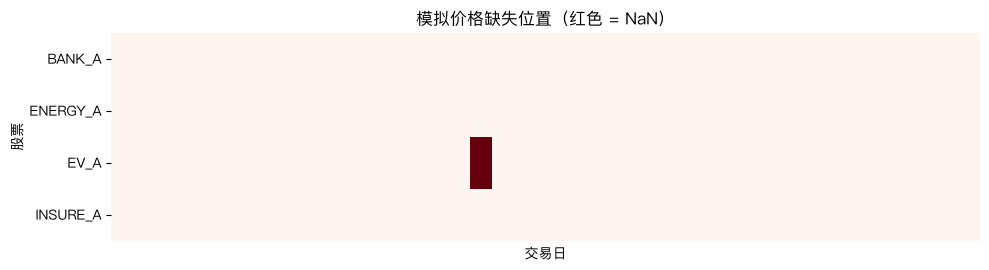

In [8]:
# 将缺失布尔矩阵画成资产 × 日期热力图。
fig, ax = plt.subplots(figsize=(10, 2.8))
sns.heatmap(
    raw_prices.isna().T,
    ax=ax,
    cmap="Reds",
    vmin=0,
    vmax=1,
    cbar=False,
    xticklabels=False,
    yticklabels=True,
)
ax.set_title("模拟价格缺失位置（红色 = NaN）")
ax.set_xlabel("交易日")
ax.set_ylabel("股票")
fig.tight_layout()
fig.savefig(
    OUTPUT_DIR / "38_missing_map.png",
    dpi=160,
    bbox_inches="tight",
)
plt.show()

## `dropna()` 的整行连累效应

`raw_prices.dropna()` 默认是 `axis=0, how="any"`：任意一列缺失就删除整行。

本例只有 `EV_A` 缺 12 日，但完整样本会从 484 日减少到 472 日，其他三只股票在这 12 日的有效观测也一起被删除。真实研究应根据目标资产集合显式使用 `subset`、`how` 或 `thresh`，并报告损失。

In [9]:
# 比较完整样本删除前后，每只股票保留下来的有效观测数。
complete_case_prices = raw_prices.dropna(
    axis=0,
    how="any",
)
dropna_impact = pd.DataFrame(
    {
        "dropna 前有效观测": raw_prices.notna().sum(),
        "dropna 后有效观测": complete_case_prices.notna().sum(),
    }
)
dropna_impact["被连带删除"] = (
    dropna_impact["dropna 前有效观测"]
    - dropna_impact["dropna 后有效观测"]
)

other_symbols = [
    symbol for symbol in selected_symbols
    if symbol != gap_symbol
]
assert complete_case_prices.shape == (472, 4)
assert raw_prices.loc[gap_dates, other_symbols].notna().all().all()
assert (dropna_impact.loc[other_symbols, "被连带删除"] == 12).all()
dropna_impact

,dropna 前有效观测,dropna 后有效观测,被连带删除
symbol,,,
BANK_A,484,472,12
ENERGY_A,484,472,12
EV_A,472,472,0
INSURE_A,484,472,12


## 停牌例子：估值价格不等于可交易价格

下面单独构造一个确定性停牌例子：

- `raw_price` 保存真实观察值，不覆盖；
- `valuation_price` 用旧价延续持仓估值；
- `tradable` 决定能否下单；
- `missing_reason` 记录停牌原因；
- 复牌价 `87.4` 相对最后有效价 `100` 的跳空为 `-12.6%`。

`ffill` 可以用于演示估值政策，但停牌日绝不能据填充值模拟成交。

In [10]:
# 分列保存原始报价、估值价、收益、可交易状态和缺失原因。
suspension_dates = pd.date_range(
    "2024-01-02",
    periods=5,
    freq="B",
)
suspension_raw_price = pd.Series(
    [100.0, np.nan, np.nan, np.nan, 87.4],
    index=suspension_dates,
    name="raw_price",
)
suspension_tradable = suspension_raw_price.notna()
suspension_valuation_price = suspension_raw_price.ffill()
suspension_valuation_return = (
    suspension_valuation_price.pct_change(fill_method=None)
)
observed_quote_return = (
    suspension_raw_price.dropna()
    .pct_change(fill_method=None)
    .reindex(suspension_dates)
)
suspension_reason = pd.Series(
    [
        "observed",
        "suspension",
        "suspension",
        "suspension",
        "observed",
    ],
    index=suspension_dates,
    name="missing_reason",
)

suspension_audit = pd.concat(
    [
        suspension_raw_price,
        suspension_valuation_price.rename("valuation_price"),
        suspension_valuation_return.rename("valuation_return"),
        observed_quote_return.rename("observed_quote_return"),
        suspension_tradable.rename("tradable"),
        suspension_reason,
    ],
    axis=1,
)

assert not suspension_tradable.iloc[1:4].any()
np.testing.assert_allclose(
    suspension_valuation_return.iloc[1:4],
    0.0,
)
assert np.isclose(suspension_valuation_return.iloc[-1], -0.126)
assert np.isclose(observed_quote_return.iloc[-1], -0.126)
suspension_audit

,raw_price,valuation_price,valuation_return,observed_quote_return,tradable,missing_reason
2024-01-02,100.0,100.0,NaN,NaN,True,observed
2024-01-03,NaN,100.0,0.000,NaN,False,suspension
2024-01-04,NaN,100.0,0.000,NaN,False,suspension
2024-01-05,NaN,100.0,0.000,NaN,False,suspension
2024-01-08,87.4,87.4,-0.126,-0.126,True,observed


### 为什么不能只在原始空值价格上直接算收益？

`raw_price.pct_change(fill_method=None)` 在复牌日看到的前一行仍是 `NaN`，因此可能无法得到跨停牌跳空。可选的透明做法是：

1. 用估值序列计算持仓价值变化，同时保留 `tradable=False`；
2. 对非空真实报价序列计算相邻有效报价收益，再把结果对齐到复牌日。

两种做法都必须保留原始报价，不能把填充值冒充真实成交价。

## 未上市与停牌必须使用不同状态

未上市前没有合法市场价格，也不属于当时投资池；停牌则是资产已经上市但暂时不可交易。二者不能只靠同一个 `NaN` 猜测。

In [11]:
# 同样是 NaN，用 listed/tradable/reason 明确区分业务状态。
listing_dates = pd.date_range(
    "2024-02-01",
    periods=4,
    freq="B",
)
listing_example = pd.DataFrame(
    {
        "raw_price": [np.nan, np.nan, 50.0, 51.0],
        "listed": [False, False, True, True],
        "tradable": [False, False, True, True],
        "missing_reason": [
            "pre_listing",
            "pre_listing",
            "observed",
            "observed",
        ],
    },
    index=listing_dates,
)

assert listing_example.loc[
    ~listing_example["listed"],
    "raw_price",
].isna().all()
assert not listing_example.loc[
    ~listing_example["listed"],
    "tradable",
].any()
listing_example

,raw_price,listed,tradable,missing_reason
2024-02-01,NaN,False,False,pre_listing
2024-02-02,NaN,False,False,pre_listing
2024-02-05,50.0,True,True,observed
2024-02-06,51.0,True,True,observed


## 宏观数据必须从公布日开始可用

月度指标可以在**公布以后**向后延续到下一次公布，但不能从所属月份月初或报告期末提前填入。

下面假设 CPI 同比在 `2024-02-15` 首次公布为 `0.7`，在 `2024-03-15` 公布新值 `0.8`。`2024-02-14` 仍必须为空。

In [12]:
# 按 available_at 对齐低频宏观数据，再沿策略交易日向后填充。
macro_releases = pd.Series(
    {
        pd.Timestamp("2024-02-15"): 0.7,
        pd.Timestamp("2024-03-15"): 0.8,
    },
    name="cpi_yoy",
)
strategy_calendar = pd.bdate_range(
    "2024-02-12",
    "2024-03-20",
)
daily_macro = macro_releases.reindex(
    strategy_calendar
).ffill()

assert pd.isna(daily_macro.loc["2024-02-14"])
assert daily_macro.loc["2024-02-15"] == 0.7
assert daily_macro.loc["2024-03-14"] == 0.7
assert daily_macro.loc["2024-03-15"] == 0.8
daily_macro.loc[
    [
        "2024-02-14",
        "2024-02-15",
        "2024-03-14",
        "2024-03-15",
    ]
].to_frame()

,cpi_yoy
2024-02-14,NaN
2024-02-15,0.7
2024-03-14,0.7
2024-03-15,0.8


## 可复用结论

1. 先审计缺失位置、比例、最长连续区间和业务原因，再选择处理方式；
2. 原始值、清洗值、缺失原因和可交易状态分列保存；
3. `ffill` 只说明没有显式读取未来，不代表价格可交易或风险没有失真；
4. `bfill` 和双侧插值若用于历史时点信号，会使用未来信息；
5. 财务和宏观特征必须按 `available_at` 与修订版本做 point-in-time 对齐。

## 方法边界

- 人工注入缺口不代表真实停牌，只用于验证代码；
- `ffill` 可能制造零收益和陈旧价格，应记录最大陈旧天数或使用 `limit`；
- 插值价格不是实际市场路径，不可用于模拟缺口期间成交；
- 停牌期间订单可能无法成交，复牌还需考虑涨跌停、流动性和成交规则；
- 未上市、退市、跨市场日历和代码变更必须分别处理；
- 对全样本使用均值填补、插值或标准化也可能引入未来信息；
- 静默删除长期停牌或退市股票会产生幸存者偏差；
- 公司行动和复权错误不能当作普通缺失值填补。

## 练习

1. 为 `raw_prices` 增加第二段零星缺失，比较总缺失数和最长连续缺失。
2. 使用 `dropna(subset=["EV_A"])`，解释它与四列完整样本的区别。
3. 给估值 `ffill` 设置 `limit=2`，观察长期缺口仍保留为空的位置。
4. 将 CPI 的值错误地放到月初并向后填充，指出哪些日期出现未来信息。